In [1]:
%pip install sentencepiece --cert /etc/ssl/certs/ca-certificates.crt


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install matplotlib


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import random
import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
import sentencepiece as spm
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# import personalized classes and configs
from configs import corpus, tok_prefix, model_config
from transformer import MultiLangDataset, TransformerModel, create_causal_mask

In [2]:
# make sure GPU is used
if not torch.cuda.is_available():
    raise RuntimeError("no GPU available")

device = torch.device('cuda:0')


In [13]:
if not os.path.exists("tokenizers"):
    os.makedirs("tokenizers")

if not os.path.exists("results"):
    os.makedirs("results")

if not os.path.exists("results/train"):
    os.makedirs("results/train")

if not os.path.exists("models"):
    os.makedirs("models")


In [4]:
# find out how many unique characters there are,
# so that I know how big to set the vocab size to in the trainer
unique_chars = set()
for curr_f in corpus["train"].values():
    with open(curr_f, encoding="utf-8") as f:
        # read whole text in as a string, then add it to a set to get unique chars
        cont = f.read().strip()
    unique_chars.update(cont)

# add 4 to vocab size to account for bos, eos, unk, pad
train_vocab_size = len(unique_chars) + 4
print(train_vocab_size)
# note: realized that the number of unique chars that I found (9447) is significantly different than what the trainer below found (Alphabet size=6393)
# That is when I discovered that the sentencepiece trainer has a default coverage parameter that is not set to 100%.
# After updating the coverage to 1.0, the new value is "Alphabet size=9328". Still don't know where the missing 119 tokens are ...

9447


In [5]:
## train the character level tokenizer
spm.SentencePieceTrainer.train(
    input=list(corpus["train"].values()), # train on all languages in the training split
    model_prefix=tok_prefix['char_level'],
    model_type='char',
    vocab_size=train_vocab_size,
    character_coverage=1.0 # keep all tokens until the vocab size is reached
)

I0000 00:00:1791740930.415701 2531344 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /srv/data/lt2326-h26/a1/train/en.txt
  input: /srv/data/lt2326-h26/a1/train/tr.txt
  input: /srv/data/lt2326-h26/a1/train/zh.txt
  input_format: 
  model_prefix: tokenizers/char_level_tok
  model_type: CHAR
  vocab_size: 9447
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  e

True

In [6]:
## train the BPE small vocab tokenizer
spm.SentencePieceTrainer.train(
    input=list(corpus["train"].values()), 
    model_prefix=tok_prefix["bpe_small"],
    model_type='bpe',
    vocab_size=10000, # todo: justify why 10,000 (has to be bigger than 9331 according to the error)
    character_coverage=1.0 # keep all tokens until the vocab size is reached - todo: should I still keep 1.0 coverage?
)

I0000 00:00:1791740930.858681 2531344 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /srv/data/lt2326-h26/a1/train/en.txt
  input: /srv/data/lt2326-h26/a1/train/tr.txt
  input: /srv/data/lt2326-h26/a1/train/zh.txt
  input_format: 
  model_prefix: tokenizers/bpe_small_tok
  model_type: BPE
  vocab_size: 10000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eo

True

In [7]:
## train the BPE large vocab tokenizer
spm.SentencePieceTrainer.train(
    input=list(corpus["train"].values()),
    model_prefix=tok_prefix["bpe_large"],
    model_type='bpe',
    vocab_size=20000, # todo: justify why 20,000 (has to be bigger than 9331 according to the error)
    character_coverage=1.0 # keep all tokens until the vocab size is reached - todo: should I still keep 1.0 coverage?
)

I0000 00:00:1791740932.955686 2531344 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /srv/data/lt2326-h26/a1/train/en.txt
  input: /srv/data/lt2326-h26/a1/train/tr.txt
  input: /srv/data/lt2326-h26/a1/train/zh.txt
  input_format: 
  model_prefix: tokenizers/bpe_large_tok
  model_type: BPE
  vocab_size: 20000
  self_test_sample_size: 0
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eo

True

In [8]:
######################
## Analyze tokenizers 
######################

# loop through tokenizer models
for i in tok_prefix.keys():
    # load the current pre-trained model
    curr_model = spm.SentencePieceProcessor(model_file=tok_prefix[i] + ".model")
    print("=========")
    print(f"MODEL: {i}")
    # get the vocab size for the current model
    print(f"vocabulary size: {curr_model.get_piece_size()}")
    print()
    
    # loop through each language split for the current model
    for lang, file in corpus["valid"].items():
        print(f"processing {lang}...")
        
        # read all the lines in the current language split,
        # to count the total number of tokens (using id) needed to encode the set
        with open(file, encoding="utf-8") as f:
            contents = f.read()
        total_num_unicode_chars = len(contents)
        encoded = curr_model.encode(contents, out_type=int)
        print(f"number of tokens needed to encode the set: {len(encoded):,}")

        # split the text on the newline character to get the sentences
        sents = contents.split("\n") # one line is one sentence
        num_sents = len(sents)

        # loop through each of the sentences in the language split
        # to calculate sentence-level metrics
        total_sent_length = 0
        for sent in sents:
            sent_encoded = curr_model.encode(sent, out_type=int)
            total_sent_length += len(sent_encoded)
    
        avg_sent_length = total_sent_length/num_sents
        print(f"average number of tokens per sentence: {avg_sent_length:.3f}")

        # number of chars in the whole text / number of tokens in the whole text
        avg_unicode_per_token = len(contents)/len(encoded) 
        print(f"average number of Unicode characters per token: {avg_unicode_per_token:.3f}")
        print()



MODEL: char_level
vocabulary size: 9331

processing en...
number of tokens needed to encode the set: 372,783
average number of tokens per sentence: 82.093
average number of Unicode characters per token: 1.000

processing tr...
number of tokens needed to encode the set: 372,114
average number of tokens per sentence: 99.602
average number of Unicode characters per token: 1.000

processing zh...
number of tokens needed to encode the set: 377,941
average number of tokens per sentence: 39.554
average number of Unicode characters per token: 1.000

MODEL: bpe_small
vocabulary size: 10000

processing en...
number of tokens needed to encode the set: 167,989
average number of tokens per sentence: 36.994
average number of Unicode characters per token: 2.219

processing tr...
number of tokens needed to encode the set: 172,981
average number of tokens per sentence: 46.301
average number of Unicode characters per token: 2.151

processing zh...
number of tokens needed to encode the set: 344,897
avera

In [9]:
## Examining sentences from the tokenizers

# loop through tokenizer models
for i in tok_prefix.keys():
    # load the current pre-trained model
    curr_model = spm.SentencePieceProcessor(model_file=tok_prefix[i] + ".model")
    print("=========")
    print(f"MODEL: {i}")
    print()
    
    # loop through each language split for the current model
    for lang, file in corpus["valid"].items():
        print(f"processing {lang}...")
        with open(file, encoding="utf-8") as f:
            lines = f.readlines()
            
        # save the first 2 sentences 
        for i in range(0,2):
            pieces = curr_model.encode(lines[i], out_type=str)
            print(pieces)
        print()
        

MODEL: char_level

processing en...
['▁', 'S', 'h', 'e', '▁', 'p', 'l', 'a', 'y', 'e', 'd', '▁', 'i', 'n', '▁', 't', 'w', 'o', '▁', 'm', 'a', 't', 'c', 'h', 'e', 's', '▁', 'a', 't', '▁', 't', 'h', 'i', 's', '▁', 'c', 'h', 'a', 'm', 'p', 'i', 'o', 'n', 's', 'h', 'i', 'p', '.']
['▁', 'A', 'f', 't', 'e', 'r', '▁', 't', 'h', 'e', 's', 'e', '▁', 'v', 'i', 'c', 't', 'o', 'r', 'i', 'e', 's', ',', '▁', 'h', 'e', '▁', 'w', 'a', 's', '▁', 'a', 'p', 'p', 'o', 'i', 'n', 't', 'e', 'd', '▁', 'a', 's', '▁', 't', 'h', 'e', '▁', 'o', 'r', 'g', 'a', 'n', 'i', 'z', 'i', 'n', 'g', '▁', 's', 'e', 'c', 'r', 'e', 't', 'a', 'r', 'y', '▁', 'o', 'f', '▁', 'D', 'M', 'K', '▁', 'i', 'n', '▁', 's', 'o', 'u', 't', 'h', 'e', 'r', 'n', '▁', 'T', 'a', 'm', 'i', 'l', '▁', 'N', 'a', 'd', 'u', '▁', 'd', 'i', 's', 't', 'r', 'i', 'c', 't', 's', '.']

processing tr...
['▁', 'G', 'e', 'r', 'm', 'a', 'n', 't', 'o', 'w', 'n', '▁', 'a', 'k', 'a', 'd', 'e', 'm', 'i', 's', 'i', 'n', 'e', '▁', 'd', 'e', 'v', 'a', 'm', '▁', 'e', 't'

In [10]:
###################################
### Part 2: the language models
###################################

def count_params(module):
    tot = 0
    for p in module.parameters():
        tot += p.numel()
    return tot


In [11]:
# Training block

# create dataset
# merge all languages from the training split - save as a list of sentences
train_text = []
for file in list(corpus["train"].values()):
    with open(file, encoding="utf-8") as f:
        curr_contents = f.readlines()
    train_text.extend(curr_contents)

# do the same for validation set
valid_text = []
for file in list(corpus["valid"].values()):
    with open(file, encoding="utf-8") as f:
        curr_contents = f.readlines()
    valid_text.extend(curr_contents)

# save training and validation loss to plot later
history = {}

# loop through tokenizer models
for i in tok_prefix.keys():
    print(f"Training model: {i}")
    # create the dataset using the current tokenizer
    tokenizer = spm.SentencePieceProcessor(model_file=tok_prefix[i] + ".model")
    # train - load data
    dataset = MultiLangDataset(train_text, tokenizer, model_config["context_len"])
    my_generator = torch.Generator().manual_seed(42)
    dataloader = DataLoader(dataset,
                            model_config["batch_size"],
                            shuffle=True,
                            generator=my_generator # make sure that it always uses same seed for shuffle
                           )
    # validation - load data
    valid_dataset = MultiLangDataset(valid_text, tokenizer, model_config["context_len"])
    valid_dataloader = DataLoader(valid_dataset,
                            model_config["batch_size"],
                            shuffle=False # do not shuffle
                           )

    # create model
    model = TransformerModel(
        num_layers=model_config["num_layers"],
        num_heads=model_config["num_heads"],
        hidden_dim=model_config["hidden_dim"],
        ff_dim=model_config["ff_dim"],
        seq_len=model_config["context_len"],
        vocab_size=tokenizer.get_piece_size(),
        device=device,
        dropout=model_config["dropout"]
    ).to(device)

    # print model parameters
    in_embedding_param_count = count_params(model.embedding)
    out_embedding_param_count = count_params(model.out)
    print(f"total model parameters: {count_params(model):,}")
    print(f"input embeddings parameter count: {in_embedding_param_count:,}")
    print(f"output layer parameter count: {out_embedding_param_count:,}\n")

    optimizer = optim.AdamW(model.parameters(), lr=model_config["lr"])
    loss_fn = nn.CrossEntropyLoss()

    best_loss = float("inf")
    history[i] = {
        "train_loss": [], 
        "valid_loss": []
    }

    # training loop
    for epoch in range(model_config["epochs"]):
        model.train()
        epoch_loss = 0

        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)

            # causal mask
            mask = create_causal_mask(X.shape[1], device)

            # forward
            optimizer.zero_grad()
            outputs = model(X, mask.unsqueeze(0))
            loss = loss_fn(outputs.view(-1, outputs.shape[-1]), y.view(-1))
            
            # backward
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),
                                           model_config["clip_norm"],
                                           error_if_nonfinite=True
                                          )

            optimizer.step()
            epoch_loss += loss.item()
                
        # evaluate on validation data
        avg_loss = epoch_loss / len(dataloader)
        model.eval()
        total_loss = 0.0
        total_tokens = 0
        with torch.no_grad():
            for X, y in valid_dataloader:
                X, y = X.to(device), y.to(device)
                mask = create_causal_mask(X.shape[1], device)
                outputs = model(X, mask.unsqueeze(0))
                loss = loss_fn(outputs.view(-1, outputs.shape[-1]), y.view(-1))
                total_loss += loss.item() * y.numel()
                total_tokens += y.numel()

        valid_loss = total_loss / total_tokens
        print(f"Epoch {epoch+1}/{model_config['epochs']}, train loss: {avg_loss:.3f}, valid loss: {valid_loss:.3f}")
        
        # save loss to history
        history[i]["train_loss"].append(avg_loss)
        history[i]["valid_loss"].append(valid_loss)
        
        if valid_loss < best_loss:
            best_loss = valid_loss
            torch.save(model.state_dict(), f"models/{i}_model_epochs{model_config["epochs"]}_batchsize{model_config["batch_size"]}.pth")

    print("========================\n")
    

Training model: char_level
total model parameters: 6,924,659
input embeddings parameter count: 2,388,736
output layer parameter count: 2,398,067

Epoch 1/20, train loss: 3.681, valid loss: 3.159
Epoch 2/20, train loss: 3.063, valid loss: 2.868
Epoch 3/20, train loss: 2.876, valid loss: 2.740
Epoch 4/20, train loss: 2.769, valid loss: 2.661
Epoch 5/20, train loss: 2.697, valid loss: 2.609
Epoch 6/20, train loss: 2.644, valid loss: 2.572
Epoch 7/20, train loss: 2.603, valid loss: 2.542
Epoch 8/20, train loss: 2.569, valid loss: 2.521
Epoch 9/20, train loss: 2.540, valid loss: 2.500
Epoch 10/20, train loss: 2.516, valid loss: 2.486
Epoch 11/20, train loss: 2.495, valid loss: 2.474
Epoch 12/20, train loss: 2.475, valid loss: 2.459
Epoch 13/20, train loss: 2.459, valid loss: 2.449
Epoch 14/20, train loss: 2.444, valid loss: 2.439
Epoch 15/20, train loss: 2.431, valid loss: 2.430
Epoch 16/20, train loss: 2.419, valid loss: 2.424
Epoch 17/20, train loss: 2.407, valid loss: 2.417
Epoch 18/20, 

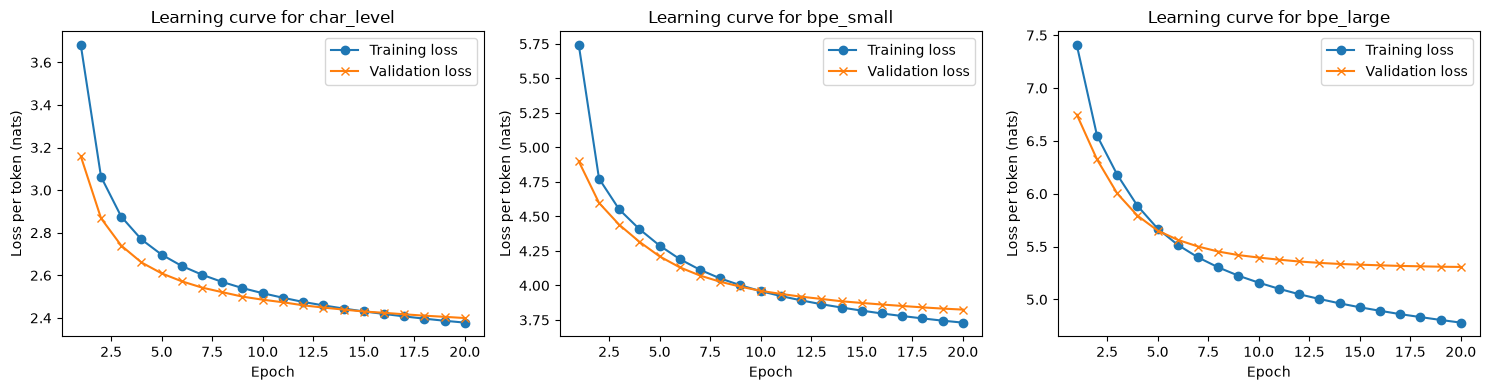

In [14]:
# plot learning curves

fig, ax = plt.subplots(nrows=1, ncols=len(history), figsize=(5*len(history), 4),
                       sharey=False, squeeze=False
                      )
ax = ax[0]
for ax_idx, (name, h) in enumerate(history.items()):
    epochs = range(1, len(h["valid_loss"]) + 1)
    ax[ax_idx].plot(epochs, h["train_loss"], marker="o", label="Training loss")
    ax[ax_idx].plot(epochs, h["valid_loss"], marker="x", label="Validation loss")

    ax[ax_idx].set_title(f"Learning curve for {name}")
    ax[ax_idx].set_xlabel("Epoch")
    ax[ax_idx].set_ylabel("Loss per token (nats)")
    ax[ax_idx].legend()

fig.tight_layout()
fig.savefig(f"results/train/learning_curves_epochs{model_config["epochs"]}_batchsize{model_config["batch_size"]}.png", dpi=200)
plt.show()
